# Sequence attributions: which bases a model uses

A sequence-to-function model predicts accessibility, footprints or
expression from DNA. **Attributions** ask the trained model which bases
drive a prediction; the bases that matter in many peaks spell out the
motifs the model has learned. Epione does this the same way for every
sequence model, through its [gReLU](https://github.com/Genentech/gReLU)
bridge (`epi.models.grelu`):

```python
from epione.models import grelu as eg
hyp   = eg.attributions(model, onehot, head=..., method='deepshap', hypothetical=True)
contr = (hyp * onehot).sum(1)                       # one value per base
motifs = eg.modisco(hyp, onehot, motifs='JASPAR.meme')   # recurring patterns, named
```

`model` can be a ChromBPNet or BPNet model, a seq2PRINT model (any LoRA
cell state), a native gReLU model, or any PyTorch module that maps one-hot
DNA to a tensor. `head` picks the output to explain (`eg.HEADS`); `method`
is DeepLIFT/SHAP (`'deepshap'`, with dinucleotide-shuffled references),
`'saliency'`, `'inputxgradient'` or `'integratedgradients'`. In-silico
mutagenesis is `eg.ism` (see [t_grelu_variants](t_grelu_variants.ipynb)).

This tutorial explains three models of human blood cells:

* **ChromBPNet**, ENCODE's bias-corrected GM12878 model (a B-lymphoblastoid
  cell line; [t_chrombpnet](t_chrombpnet.ipynb)), log-count head;
* **seq2PRINT**, the PBMC model of [t_seq2print](t_seq2print.ipynb), in its
  B-cell and CD14-monocyte LoRA states, both for coverage and for the
  TF-sized footprints (`head='footprint_tf'`, the output scPrinter's TF
  binding scores are built on).

Run [t_seq2print](t_seq2print.ipynb) first: this notebook loads the models
it trains and caches.

## Part 1 · Setup

In [1]:
%matplotlib inline
import os, sys, pathlib, re, warnings, logging
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


def _find_repo(start):
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

import epione as epi
from epione.models import chrombpnet as cbp
from epione.models import grelu as eg
import grelu.lightning  # noqa: F401  (import first: Lightning resets its log level on import)
for name in ('lightning', 'lightning.pytorch', 'pytorch_lightning', 'lightning_fabric'):
    logging.getLogger(name).setLevel(logging.ERROR)
s2p = epi.models.seq2print

DATA = os.environ.get('EPIONE_TUTORIAL_DATA')
files = epi.datasets.pbmc10k_multiome_atac(pathlib.Path(DATA) / 'pbmc10k_multiome' if DATA else None)
WORK = files['fragments'].parent / 'seq2print_work'          # t_seq2print's cache
FASTA = str(epi.data.hg38.fasta)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
epi.pl.plot_set()

# ChromBPNet: ENCODE GM12878, bias-corrected, fold 0
chrombpnet = cbp.load_pretrained('encode_gm12878', 'nobias', fold=0).to(DEVICE).eval()

# seq2PRINT: the bulk backbone + one LoRA state per cell type (t_seq2print)
TYPES = ['CD14 Mono', 'CD16 Mono', 'DC', 'B', 'CD4 T', 'CD8 T', 'NK']
seq2print = s2p.build_seq2print()
seq2print.load_state_dict(torch.load(WORK / 'bulk_fold0_40000.pt', map_location='cpu'))
seq2print.add_lora(np.load(WORK / 'lora_emb.npy'), coverages=np.load(WORK / 'lora_cov.npy'),
                   rank=8, hidden_dim=64)
seq2print.load_state_dict(torch.load(WORK / 'lora_celltype_40000_8000_1500.pt', map_location='cpu'))
seq2print = seq2print.to(DEVICE).eval()
B, MONO = TYPES.index('B'), TYPES.index('CD14 Mono')
state = {'B': seq2print.collapse(B).eval(), 'CD14 Mono': seq2print.collapse(MONO).eval()}
print(f'ChromBPNet input {chrombpnet.input_len} bp; seq2PRINT input {seq2print.dna_len} bp')
eg.HEADS

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



ChromBPNet input 2114 bp; seq2PRINT input 1840 bp


{'bpnet': ('counts', 'profile', 'profile_logits', 'expected_counts'),
 'chrombpnet': ('counts', 'profile', 'profile_logits', 'expected_counts'),
 'seq2print': ('coverage', 'footprints', 'footprint_tf'),
 'module': ('output',)}

## Part 2 · Motifs each model has learned

The bases that matter in many peaks spell out the motifs a model uses.
`eg.modisco` clusters high-attribution stretches (seqlets) from many
peaks with TF-MoDISco (modiscolite) and names each pattern by its best
TOMTOM match in JASPAR 2024. Five runs, each on 2,000 peaks called most
strongly in one cell type ([t_seq2print](t_seq2print.ipynb), Part 3):

| run | model, output | peaks |
|---|---|---|
| ChromBPNet | GM12878, log counts | B cells |
| seq2PRINT B | B-cell state, TF footprints | B cells |
| seq2PRINT Mono, coverage | monocyte state, coverage | CD14 monocytes |
| seq2PRINT Mono | monocyte state, TF footprints | CD14 monocytes |
| seq2PRINT B on Mono peaks | B-cell state, TF footprints | CD14 monocytes |

The last run reads exactly the sequences of the fourth with the B-cell
state, so any difference between them comes from the cell type the model
is conditioned on. Each run takes 1-3 minutes of attributions on an H100
and about a minute of TF-MoDISco.

In [2]:
%%time
MEME = WORK / 'JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt'
if not MEME.exists():
    import urllib.request
    urllib.request.urlretrieve('https://jaspar.elixir.no/download/data/2024/CORE/' + MEME.name, MEME)
jaspar = eg.read_meme(MEME)                                 # {'MA0102.5 CEBPA': [4, w], ...}

peaks = pd.read_csv(WORK / 'peaks_celltype.tsv', sep='\t').sort_values('score', ascending=False)
top = {t: peaks[peaks['group'] == t].head(2000).reset_index(drop=True) for t in ('B', 'CD14 Mono')}
RUNS = {
    'ChromBPNet\nB peaks': ('B', chrombpnet, 'counts'),
    'seq2PRINT B\nB peaks': ('B', state['B'], 'footprint_tf'),
    'seq2PRINT Mono\ncoverage': ('CD14 Mono', state['CD14 Mono'], 'coverage'),
    'seq2PRINT Mono\nMono peaks': ('CD14 Mono', state['CD14 Mono'], 'footprint_tf'),
    'seq2PRINT B\nMono peaks': ('CD14 Mono', state['B'], 'footprint_tf'),
}
motifs, contrib = {}, {}
for name, (ctype, model, head) in RUNS.items():
    L = chrombpnet.input_len if model is chrombpnet else seq2print.dna_len
    X = s2p.one_hot_regions(FASTA, top[ctype], length=L)
    hyp = eg.attributions(model, X, head=head, method='deepshap', hypothetical=True,
                          n_shuffles=20, seed=0, device=DEVICE, batch_size=32)
    motifs[name] = eg.modisco(hyp, X, window=400, motifs=MEME)
    if ctype == 'CD14 Mono' and head == 'footprint_tf':
        contrib[name] = (hyp * X).astype(np.float32)            # kept for Part 3
    t = motifs[name].table
    print(f"{name.replace(chr(10), ', ')}: {len(t)} patterns;",
          ', '.join(f"{m.split()[1]} ({n})" for m, n in zip(t['match'], t['n_seqlets'])))

ChromBPNet, B peaks: 7 patterns; STAT1::STAT2 (567), Spi1 (415), REL (176), Spi1 (38), EBF3 (23), Bcl11B (21), POU2F3 (20)


seq2PRINT B, B peaks: 7 patterns; Spi1 (593), STAT1::STAT2 (398), Irf1 (106), CTCF (78), REL (60), KLF5 (49), CREB3L4 (30)


seq2PRINT Mono, coverage: 8 patterns; SPIB (810), CEBPA (522), BACH1 (131), CREB3L4 (78), STAT1::STAT2 (63), Nrf1 (37), CTCF (32), NFYA (29)


seq2PRINT Mono, Mono peaks: 10 patterns; CEBPA (479), SPIB (326), FOSL2::JUN (130), Nrf1 (128), TFEC (78), NFYA (50), STAT1::STAT2 (44), CTCF (43), CTCF (38), FOS::JUND (35)


seq2PRINT B, Mono peaks: 12 patterns; NFYA (220), Spi1 (206), ETV6 (192), Nrf1 (176), Irf1 (150), KLF7 (148), FOSL2::JUN (120), TFEC (80), CTCF (78), STAT1::STAT2 (48), CTCF (27), RFX5 (24)
CPU times: user 1h 37min 7s, sys: 7 s, total: 1h 37min 14s
Wall time: 15min 41s


In [3]:
motifs['seq2PRINT Mono\nMono peaks'].table[['pattern', 'n_seqlets', 'consensus', 'match', 'pval',
                                           'match_2', 'pval_2']]

,pattern,n_seqlets,consensus,match,pval,match_2,pval_2
0,pos_0,479,ATTGTGCAAT,MA0102.5 CEBPA,1.268703e-09,MA0836.3 CEBPD,2.457033e-07
1,pos_1,326,ACTTCCTCTTT,MA0081.3 SPIB,2.905076e-11,MA0080.7 Spi1,2.574406e-10
2,pos_2,130,TGACGTCA,MA1131.2 FOSL2::JUN,3.659681e-09,MA1127.1 FOSB::JUN,3.149141e-08
3,pos_3,128,TGCGCATGCGC,MA0506.3 Nrf1,1.310119e-07,MA0472.2 EGR2,1.026988e-03
4,pos_4,78,GTCACGTG,MA0871.3 TFEC,1.046678e-08,MA0058.4 MAX,9.529615e-07
5,pos_5,50,CCAAT,MA0060.4 NFYA,9.427779e-05,MA0502.3 NFYB,2.797908e-04
6,pos_6,44,ACTTTCGCTTCC,MA0517.2 STAT1::STAT2,1.263523e-07,MA0772.2 IRF7,4.549370e-07
7,pos_7,43,CCGCCCCCTGGTGG,MA0139.2 CTCF,9.114710e-16,MA1930.2 CTCF,8.941120e-14
8,pos_8,38,AAGGGGCCCGGAAGTGACGCAAC,MA1929.2 CTCF,3.304871e-07,MA1930.2 CTCF,6.494793e-07
9,pos_9,35,ATGACTCA,MA1141.2 FOS::JUND,6.291916e-07,MA0477.3 FOSL1,6.291916e-07


Each pattern is a cluster of seqlets, named by the JASPAR motif it
matches best. The dot plot groups the matches into TF families; dot size
is the number of seqlets.

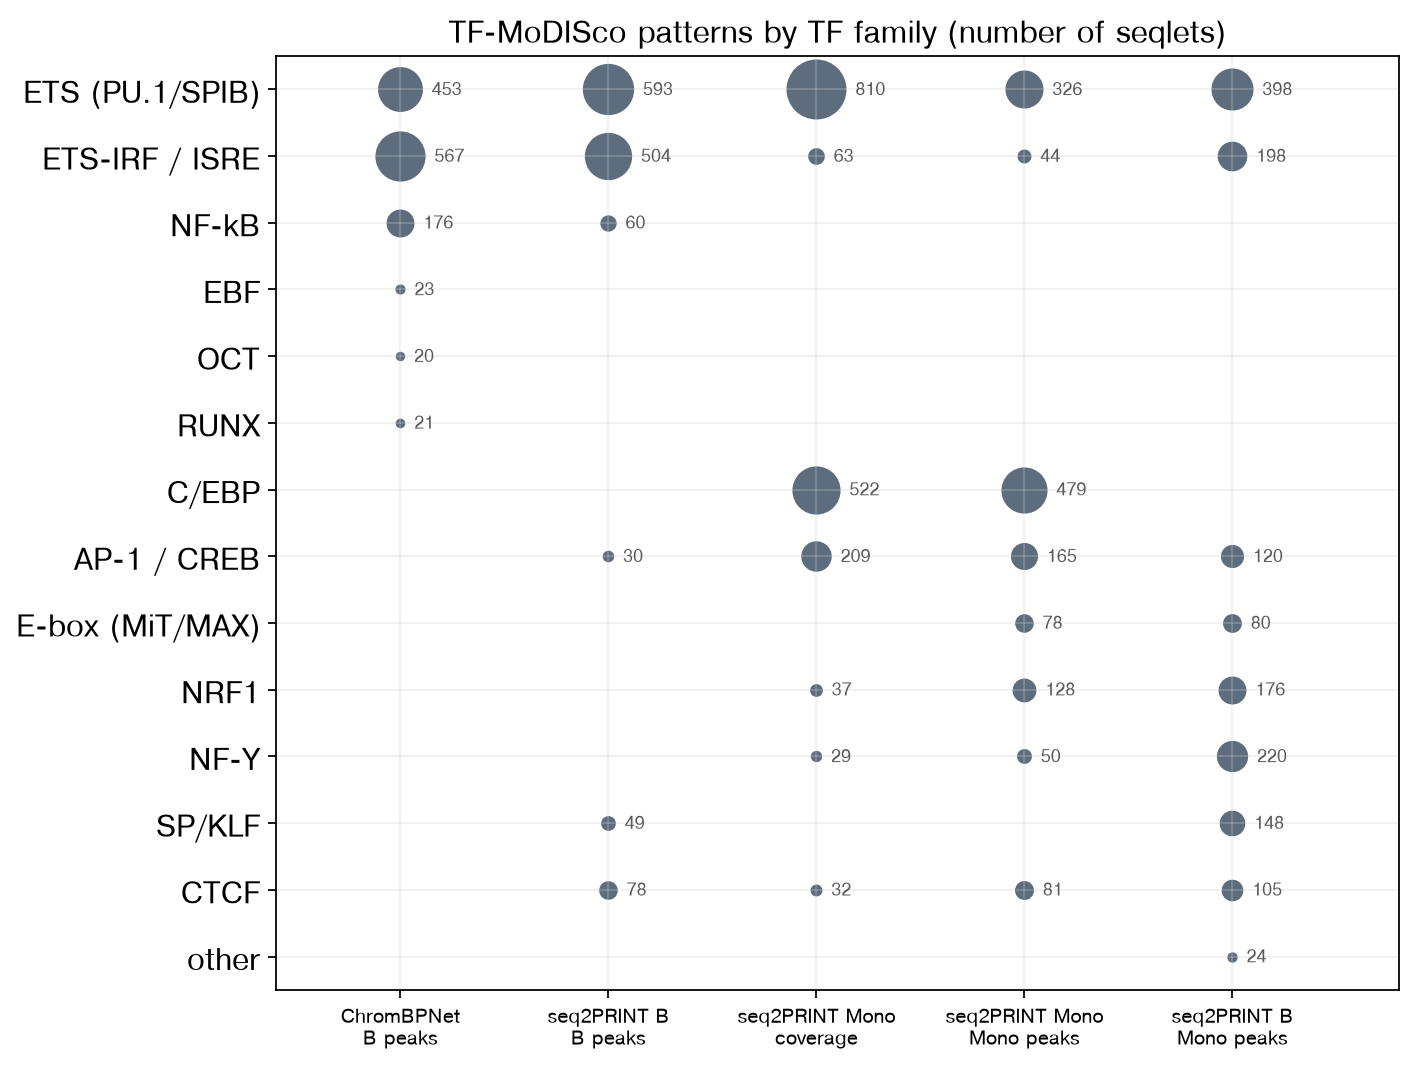

In [4]:
FAMILIES = [('ETS (PU.1/SPIB)', r'SPI1|SPIB|ELF|ETS|ETV|FLI1|GABPA|ELK|ERG'),
            ('ETS-IRF / ISRE', r'IRF|STAT'),
            ('NF-kB', r'REL|NFKB'),
            ('EBF', r'EBF'),
            ('OCT', r'POU'),
            ('RUNX', r'RUNX|BCL11'),
            ('C/EBP', r'CEBP|DDIT3'),
            ('AP-1 / CREB', r'FOS|JUN|BATF|BACH|CREB|ATF|NFE2|MAF'),
            ('E-box (MiT/MAX)', r'TFE|MITF|MAX|USF|HES|MYC'),
            ('NRF1', r'NRF1'),
            ('NF-Y', r'NFY'),
            ('SP/KLF', r'^SP\d|KLF|PATZ|ZNF'),
            ('CTCF', r'CTCF')]


def family(row):
    for col in ('match', 'match_2', 'match_3'):
        tf = str(row[col]).split()[-1].upper()
        for fam, pat in FAMILIES:
            if re.search(pat, tf):
                return fam
    return 'other'


dots = []
for name, r in motifs.items():
    t = r.table[r.table['sign'] == 'pos'].copy()
    t['family'] = t.apply(family, axis=1)
    for fam, n in t.groupby('family')['n_seqlets'].sum().items():
        dots.append((name, fam, n))
dots = pd.DataFrame(dots, columns=['run', 'family', 'seqlets'])
fams = [f for f, _ in FAMILIES if f in set(dots.family)] + (['other'] if 'other' in set(dots.family) else [])
runs = list(motifs)
fig, ax = plt.subplots(figsize=(9, 0.42 * len(fams) + 1.8))
for _, d in dots.iterrows():
    ax.scatter(runs.index(d.run), fams.index(d.family), s=d.seqlets * 0.9, color='#34495e', alpha=0.8, lw=0)
    ax.annotate(int(d.seqlets), (runs.index(d.run), fams.index(d.family)),
                xytext=(4 + 0.5 * np.sqrt(d.seqlets * 0.9), 0),
                textcoords='offset points', va='center', fontsize=8, color='0.35')
ax.set_xticks(range(len(runs)), runs, fontsize=9); ax.set_yticks(range(len(fams)), fams)
ax.set_xlim(-0.6, len(runs) - 0.2); ax.set_ylim(len(fams) - 0.5, -0.5)
ax.grid(alpha=0.3); ax.set_title('TF-MoDISco patterns by TF family (number of seqlets)')
plt.show()

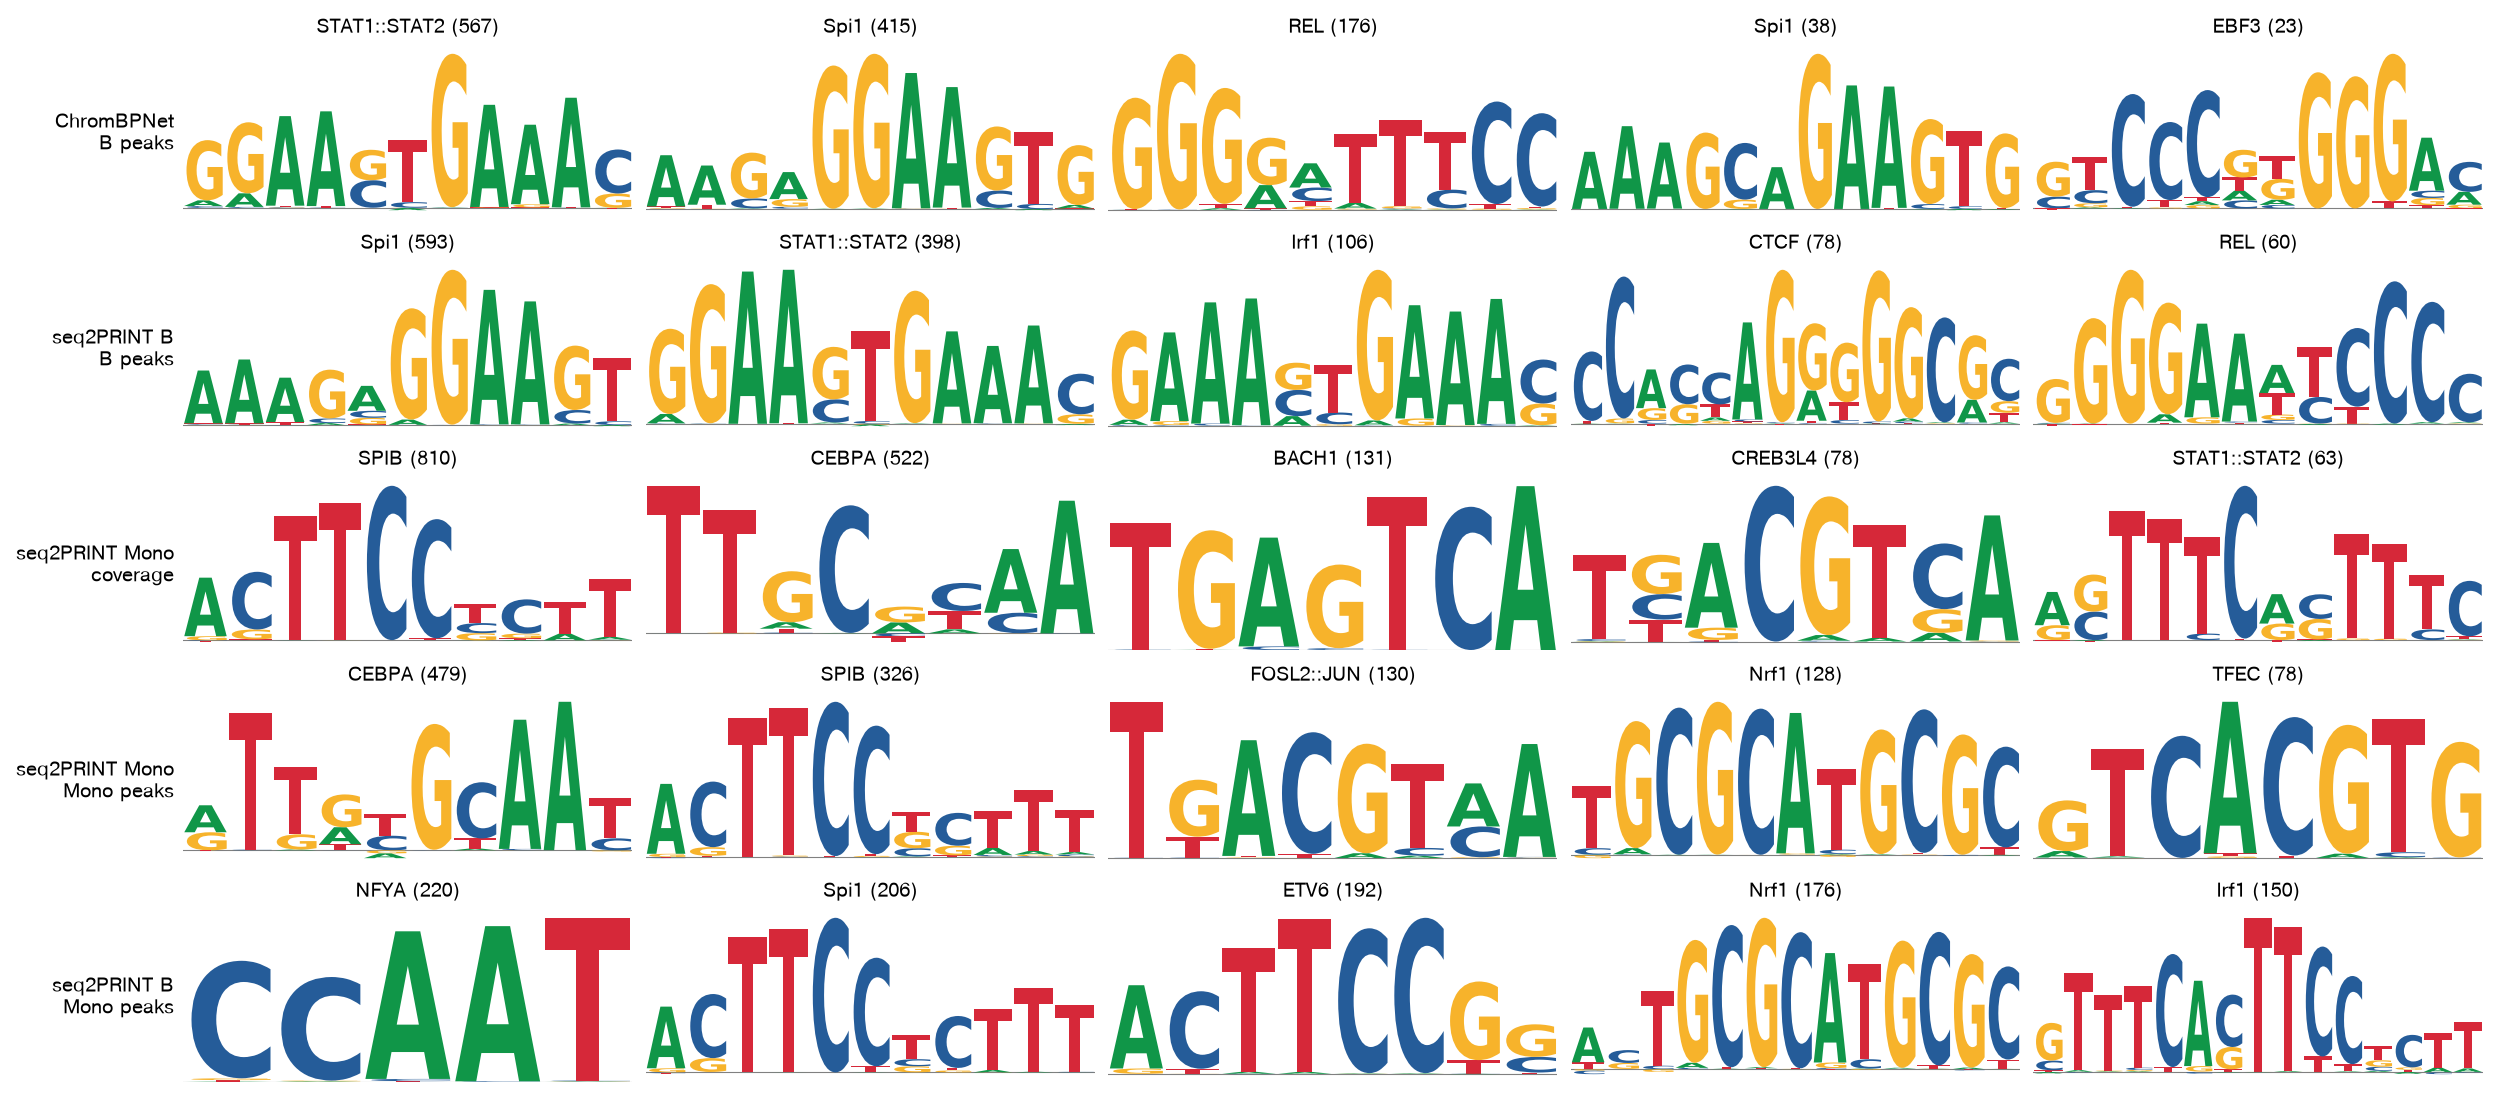

In [5]:
TOP = 5
fig, axes = plt.subplots(len(motifs), TOP, figsize=(3.1 * TOP, 1.35 * len(motifs)), layout='constrained')
for i, (name, r) in enumerate(motifs.items()):
    t = r.table[r.table['sign'] == 'pos'].head(TOP)
    for j in range(TOP):
        ax = axes[i, j]
        if j < len(t):
            row = t.iloc[j]
            epi.pl.plot_seqlogo(r.contrib[row['pattern']], ax=ax)
            ax.set_title(f"{row['match'].split()[1]} ({row['n_seqlets']})", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
    axes[i, 0].set_ylabel(name, rotation=0, ha='right', va='center', fontsize=9)
plt.show()

What the runs share and where they differ:

* **ETS (PU.1, SPIB)** is a top pattern in every run. PU.1 is expressed in
  both B cells and monocytes, and in the GM12878 line ChromBPNet was
  trained on.
* **B cells.** ChromBPNet and the B-cell state both find the ETS-IRF
  composite element (`GGAAGTGAAA`, where PU.1 or SPIB binds with IRF4/IRF8;
  567 and 504 seqlets) and NF-kB (176 and 60). ChromBPNet also finds small
  EBF, OCT and RUNX patterns.
* **Monocytes.** C/EBP is the monocyte state's top pattern, for TF
  footprints (479 seqlets) and for coverage (522), followed by ETS, AP-1 /
  CREB, NRF1, a MiT-family E-box (TFEC) and NF-Y. The ETS-IRF element is
  nearly absent (44).
* **Same peaks, other state.** Read by the B-cell state, the same 2,000
  monocyte peaks give no C/EBP pattern at all. Their seqlets go to promoter
  motifs instead (NF-Y 220, NRF1 176, SP/KLF 148) and to ETS-IRF (198): the
  model ties C/EBP to monocytes, and the LoRA state carries that.
* **CTCF** is found by the TF-footprint output in both states. It leaves a
  strong footprint wherever it binds.

ChromBPNet sees more B-cell motifs than the seq2PRINT B-cell state. It is a
full model trained on one deep cell line, whereas the B-cell state is a
light LoRA update trained on 735 cells; [t_seq2print](t_seq2print.ipynb)
shows the same limit for PAX5 and EBF1 sites.

## Part 3 · One CEBPA site, two cell types

To see what the dot plot summarises, take one monocyte peak and look at
the bases. For every CEBPA motif match (JASPAR, p < 10⁻⁴) within 200 bp of
the summits of the 2,000 monocyte peaks, we measure the share of the
window's attribution (|contribution| over the central 400 bp) that falls on
the motif, in each state. A share, unlike the raw values, does not depend
on how large the two states' outputs are. The logos show the site where
the monocyte state's share exceeds the B-cell state's the most.

612 CEBPA matches. Share of the window attribution on the motif (10 of 400 bp): median 14.9% in the monocyte state, 2.3% in the B-cell state; larger in the monocyte state at 97%.


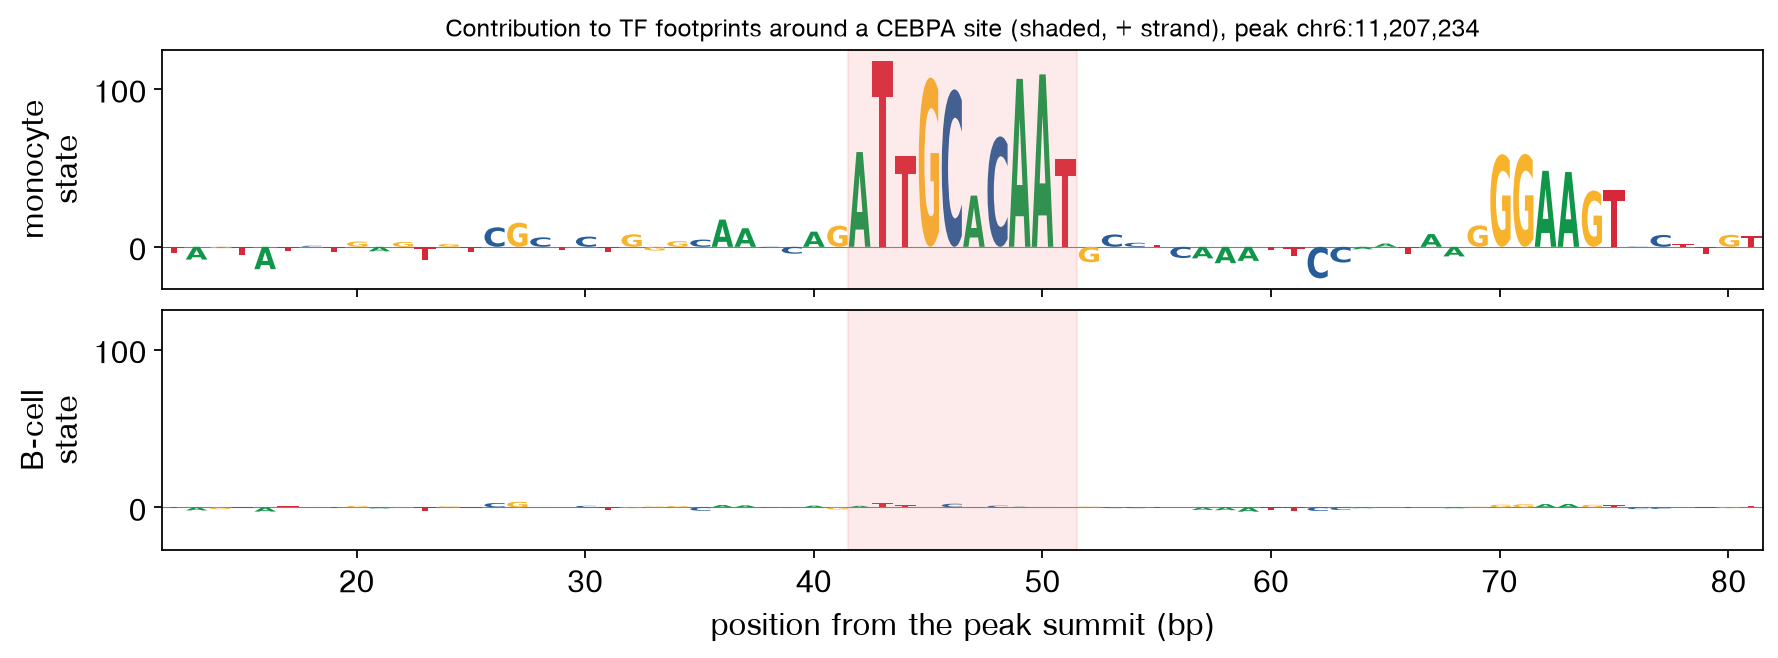

In [6]:
mono = top['CD14 Mono']
cebpa = next(v for k, v in jaspar.items() if k.split()[1].upper() == 'CEBPA')
win = mono.assign(start=mono.summit - 200, end=mono.summit + 200)[['chrom', 'start', 'end']]
hits = epi.tl.hint_match_motifs(win, {'CEBPA': (cebpa * 100).round().tolist()}, FASTA, fpr=1e-4)
hits = (hits.merge(win.rename(columns={'start': 'ws', 'end': 'we'}).reset_index(), on='chrom')
            .query('start >= ws and end <= we').reset_index(drop=True))
L = seq2print.dna_len
cm, cb = contrib['seq2PRINT Mono\nMono peaks'], contrib['seq2PRINT B\nMono peaks']
off = (hits['start'] - (mono.summit.to_numpy()[hits['index']] - L // 2)).to_numpy()
w = int((hits.end - hits.start).iloc[0])
c0 = L // 2 - 200                                       # central 400 bp


def share(c, i, o):
    a = np.abs(c[i, :, c0:c0 + 400]).sum()
    return np.abs(c[i, :, o:o + w]).sum() / a


sm = np.array([share(cm, i, o) for i, o in zip(hits['index'], off)])
sb = np.array([share(cb, i, o) for i, o in zip(hits['index'], off)])
print(f'{len(hits)} CEBPA matches. Share of the window attribution on the motif '
      f'({w} of 400 bp): median {np.median(sm):.1%} in the monocyte state, '
      f'{np.median(sb):.1%} in the B-cell state; larger in the monocyte state at {np.mean(sm > sb):.0%}.')
k = int(np.argmax(sm - sb)); i, o = int(hits['index'][k]), int(off[k])

fig, axes = plt.subplots(2, 1, figsize=(11, 4), sharex=True, layout='constrained')
lo = o - 30
for ax, (name, c) in zip(axes, (('monocyte\nstate', cm), ('B-cell\nstate', cb))):
    epi.pl.plot_seqlogo(c[i, :, lo:o + w + 30], ax=ax, start=lo - L // 2)
    ax.axvspan(o - L // 2 - 0.5, o + w - L // 2 - 0.5, color='#EF7B77', alpha=0.15)
    ax.set_ylabel(name)
ymin = min(a.get_ylim()[0] for a in axes); ymax = max(a.get_ylim()[1] for a in axes)
for ax in axes:
    ax.set_ylim(ymin, ymax)
axes[-1].set_xlabel('position from the peak summit (bp)')
axes[0].set_title(f"Contribution to TF footprints around a CEBPA site (shaded, {hits.strand[k]} strand), "
                  f"peak {mono.chrom[i]}:{int(mono.summit[i]):,}", fontsize=11)
plt.show()

In the monocyte state the CEBPA site (`ATTGCACAAT`) carries most of the
attribution in its neighbourhood, together with a PU.1 motif (`GGAAGT`)
25 bp downstream. The B-cell state reads the same bases and gives both
almost nothing. Across all 612 CEBPA matches, the motif's 10 bases carry a
median 14.9% of the window's attribution in the monocyte state and 2.3% in
the B-cell state, about what any 10 of 400 bases would carry (2.5%); the
monocyte state's share is larger at 97% of the sites.

This is the per-base evidence behind [t_seq2print](t_seq2print.ipynb)'s
CEBPA binding scores, which are much higher in monocytes than in T cells.

## Summary

| | |
|---|---|
| Attributions | `eg.attributions(model, onehot, head=..., method='deepshap', hypothetical=True)`; also `'saliency'`, `'inputxgradient'`, `'integratedgradients'`; ISM is `eg.ism` |
| Models | ChromBPNet / BPNet (`'counts'`, `'profile'`, ...), seq2PRINT (`'coverage'`, `'footprints'`, `'footprint_tf'`; LoRA states via `collapse(state)` or `cells=`), native gReLU models, any one-hot `nn.Module` |
| Logos | `epi.pl.plot_seqlogo(contribution)` |
| Motifs | `eg.modisco(hyp, onehot, motifs='JASPAR.meme')`: TF-MoDISco patterns named by TOMTOM |
| TF binding per base | seq2PRINT only: `s2p.tf_binding` ([t_seq2print](t_seq2print.ipynb)) |
| Cell-state LoRA | explain each state with `model.collapse(state)`; the same sequences read by two states show what the cell type changes |